<a href="https://colab.research.google.com/github/guyen5/Minerva-Capstone/blob/main/D2.%20Per-ETF%20Forecast%20Test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# D2 Per-ETF Forecast Test

**Diagnostic.**

Even with almost no penalty, the pooled PTO forecasts differ across ETFs by only about half as much as realized returns do, too little to reproduce the paper's turnover. The paper writes its predictor as r̂ = Θx + b with a separate row of Θ for each asset (Eq. 29). This notebook tests whether a separate unpenalized regression per ETF reproduces the paper's PTO turnover.

**Variants**, all on the 9+3 window (all 12 months, since nothing is tuned):

| Variant | Model | Rows per fit |
|---|---|---|
| Pooled, daily | One ridge model for all ETFs, penalty 0.1 | about 2,000 daily rows |
| Per-ETF, daily | Least-squares regression per ETF on its own seven features | about 250 daily rows |
| Per-ETF, month-end | The same, on month-end rows only | 11 |

**Rule, fixed before the run.** A per-ETF variant reproduces the paper if it passes criteria 1 and 2 of the replication run on ETF_A over the first 70 months. If one passes, it becomes plain PTO (the daily version if both pass). If neither passes, the replication is partial and plain PTO stays the pooled least-penalized model.

**Inputs:** Daily Prices, Monthly Data, Daily Features, Daily Training Windows, Covariances

**Output:** D2 Per-ETF Forecast Results.csv (`data/reports`): turnover, Sharpe ratio and forecast quality of every variant

## 1. Setup

Mounts Google Drive and loads the project code from GitHub.

In [1]:
# Google Drive with the data folder
from google.colab import drive
drive.mount("/content/drive")

import shutil
import subprocess
import sys

# Project code from GitHub
REPO_DIR = "/content/Minerva-Capstone"
shutil.rmtree(REPO_DIR, ignore_errors=True)
subprocess.run(["git", "clone", "--quiet", "https://github.com/guyen5/Minerva-Capstone.git", REPO_DIR],
               check=True)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--date=format:%Y-%m-%d %H:%M",
                      "--format=Code version: %h, %s (%cd)"], capture_output=True, text=True).stdout)

# Pinned libraries and the project modules
%pip install --quiet -r {REPO_DIR}/requirements.txt
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive
Code version: eda1dbb, Diagnostic (2026-10-30 16:13)



In [2]:
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import backtest, cleaning, config, forecast, windows

# Reload after a fresh clone
for module in (config, cleaning, windows, backtest, forecast):
    importlib.reload(module)

# Data folder paths
DIRS = config.data_dirs()
pd.set_option("display.width", 170)

## 2. Load the inputs

In [3]:
proc = DIRS["processed"]
clean = cleaning.load_clean(proc)
panel = pd.read_parquet(proc / config.FILES["monthly"])
daily_table = pd.read_parquet(proc / config.FILES["daily_table"])
all_windows = pd.read_parquet(proc / config.FILES["daily_windows"])
cov_table = pd.read_parquet(proc / config.FILES["covariances"])

# Decision calendar, holding-month returns, sample covariances and historical means
calendar = all_windows[all_windows["window"] == "9+3"].reset_index(drop=True)
universes = ("ETF_A", "ETF_B")
returns = {u: backtest.holding_returns(panel, u) for u in universes}
cov_sample = {u: backtest.covariance_lookup(cov_table, u, "sample") for u in universes}
hist_mu = {u: backtest.historical_means(clean, returns[u].index, u) for u in universes}
paper = backtest.paper_rows("PTO").set_index(["universe", "lam"])
print(f"{len(calendar)} decision dates, {calendar['month'].iloc[0]} to {calendar['month'].iloc[-1]}")

81 decision dates, 2020-01 to 2026-09


## 3. Per-ETF forecasts

For each decision date and ETF, an ordinary least-squares regression of the 21-day forward return on that ETF's seven features and an intercept, fitted on the window's rows for that ETF.

In [4]:
def per_etf_forecasts(universe, month_end_only):
    """Forecasts from one least-squares regression per ETF and decision date."""
    tickers = backtest.tickers_of(universe)
    rows = []
    for _, step in calendar.iterrows():
        fit, val, test = windows.daily_rows_for(daily_table, step, universe)
        train = pd.concat([fit, val])
        if month_end_only:
            train = train[train["month_end"]]
        for t in tickers:
            tr = train[train["ticker"] == t]
            x = np.column_stack([np.ones(len(tr)), tr[config.FEATURES].to_numpy(float)])
            beta, *_ = np.linalg.lstsq(x, tr["fwd_return"].to_numpy(float), rcond=None)
            xt = test[test["ticker"] == t][config.FEATURES].to_numpy(float)
            rows.append({"date": step["decision_date"], "month": step["month"], "universe": universe,
                         "ticker": t, "forecast": float(beta[0] + xt[0] @ beta[1:]), "rows": len(tr)})
    return pd.DataFrame(rows)


forecasts = {}
for u in universes:
    forecasts[("Pooled, daily", u)] = forecast.build_forecasts(
        daily_table, calendar, u, backtest.tickers_of(u), alphas=[config.PTO_ALPHA_GRID[0]])
    forecasts[("Per-ETF, daily", u)] = per_etf_forecasts(u, month_end_only=False)
    forecasts[("Per-ETF, month-end", u)] = per_etf_forecasts(u, month_end_only=True)

# Every training return known on its decision date; every forecast present
label = daily_table.drop_duplicates("date").set_index("date")["label_date"]
assert all(label.loc[s["train_start"]:s["train_end"]].max() <= s["decision_date"] for _, s in calendar.iterrows())
for (name, u), f in forecasts.items():
    assert f["forecast"].notna().all() and len(f) == len(calendar) * len(backtest.tickers_of(u))
print("Rows per fit, per-ETF month-end, ETF_A (median)")
print(forecasts[("Per-ETF, month-end", "ETF_A")].groupby("ticker")["rows"].median().to_string())

Rows per fit, per-ETF month-end, ETF_A (median)
ticker
AGG     11.0
DBC     11.0
EEM     11.0
EFA     11.0
JPXN    11.0
SPY     11.0
VTI     11.0
XLK     11.0


## 4. Forecast quality

The spread ratio is the cross-ETF spread of forecasts divided by that of realized returns. The chart shows the best-minus-worst gap across ETFs each month.

                             oos_r2  mean_ic  ic_t_stat  top_pick_beats_average  spread_ratio
variant            universe                                                                  
Pooled, daily      ETF_A     -0.262    0.120      2.130                   0.519         0.532
Per-ETF, daily     ETF_A     -0.912   -0.017     -0.307                   0.457         0.958
Per-ETF, month-end ETF_A     -5.862    0.113      2.382                   0.605         3.081
Pooled, daily      ETF_B     -0.419   -0.026     -0.480                   0.432         0.507
Per-ETF, daily     ETF_B     -0.963   -0.013     -0.270                   0.481         0.924
Per-ETF, month-end ETF_B     -5.488   -0.044     -1.066                   0.506         2.983


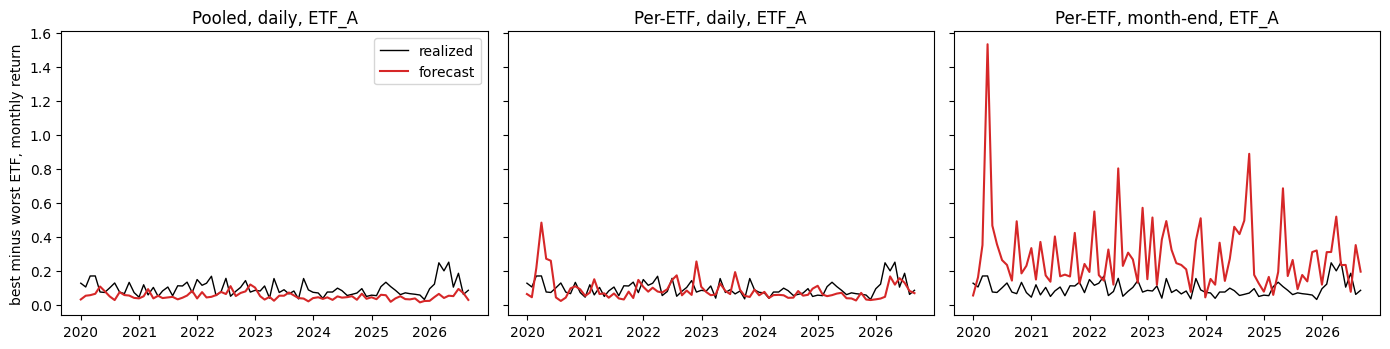

In [5]:
quality = pd.concat([forecast.forecast_quality(f, panel).assign(variant=name)
                     for (name, u), f in forecasts.items()]).reset_index()
quality = quality.drop_duplicates(["variant", "universe"]).set_index(["variant", "universe"])
print(quality.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
real = panel[["date", "universe", "ticker", "next_return"]]
for ax, name in zip(axes, ("Pooled, daily", "Per-ETF, daily", "Per-ETF, month-end")):
    m = forecasts[(name, "ETF_A")].merge(real, on=["date", "universe", "ticker"])
    spread = m.groupby("date")[["forecast", "next_return"]].agg(lambda s: s.max() - s.min())
    ax.plot(spread.index, spread["next_return"], color="black", lw=1, label="realized")
    ax.plot(spread.index, spread["forecast"], color="tab:red", lw=1.5, label="forecast")
    ax.set_title(f"{name}, ETF_A")
axes[0].set_ylabel("best minus worst ETF, monthly return")
axes[0].legend()
plt.tight_layout()
plt.show()

## 5. Backtests

Each variant through the optimizer and accounting of the replication run, for every λ, next to classic Markowitz (first 70 months).

In [6]:
runs, weights = [], {}
plans = [(name, u, f.pivot(index="date", columns="ticker", values="forecast")[backtest.tickers_of(u)])
         for (name, u), f in forecasts.items()]
plans += [("Classic Markowitz", u, hist_mu[u]) for u in universes]
for name, u, mu in plans:
    for lam in config.LAMBDA_GRID:
        mo, w = backtest.run(backtest.mean_variance(mu, cov_sample[u], lam), returns[u])
        assert (backtest.check_accounting(mo, w, returns[u])["status"] == "PASS").all()
        runs.append(mo.assign(strategy=name, universe=u, lam=lam))
        weights[(name, u, lam)] = w

months = pd.concat(runs, ignore_index=True)
first70 = months[months["month"] <= config.PAPER_LAST_MONTH]
summary = pd.DataFrame([backtest.metrics(g).rename(k) for k, g in first70.groupby(["strategy", "universe", "lam"])])
summary.index.names = ["strategy", "universe", "lam"]
summary = summary.join(paper[["turnover", "sharpe"]].add_prefix("paper_"), on=["universe", "lam"])

order = ["Classic Markowitz", "Pooled, daily", "Per-ETF, daily", "Per-ETF, month-end"]
for metric in ("turnover", "sharpe"):
    view = summary[metric].unstack("strategy")[order]
    view["paper PTO"] = paper[metric]
    print(f"{metric}, first 70 months")
    print(view.round(3).to_string())
    print()

turnover, first 70 months
strategy       Classic Markowitz  Pooled, daily  Per-ETF, daily  Per-ETF, month-end  paper PTO
universe lam                                                                                  
ETF_A    0.1               0.170          0.341           0.598               0.741      0.831
         1.0               0.180          0.348           0.589               0.753      0.831
         10.0              0.127          0.282           0.515               0.787      0.831
         20.0              0.081          0.198           0.394               0.741      0.831
         50.0              0.046          0.103           0.208               0.625      0.838
ETF_B    0.1               0.111          0.399           0.658               0.829      0.901
         1.0               0.132          0.415           0.658               0.824      0.901
         10.0              0.142          0.313           0.551               0.833      0.896
         20.0           

## 6. Criteria and the rule

In [7]:
hi = [l for l in config.LAMBDA_GRID if l >= 10]
mvo = summary.loc[("Classic Markowitz", "ETF_A")]
rows = []
for name in ("Pooled, daily", "Per-ETF, daily", "Per-ETF, month-end"):
    a = summary.loc[(name, "ETF_A")].sort_index()
    change = abs(a.loc[50.0, "turnover"] - a.loc[0.1, "turnover"])
    ratio = a.loc[hi, "turnover"] / mvo.loc[hi, "turnover"]
    rows.append({"variant": name, "turnover": f"{a['turnover'].min():.2f} to {a['turnover'].max():.2f}",
                 "change λ 0.1 to 50": round(change, 3),
                 "ratio to Markowitz, λ ≥ 10": ", ".join(f"{r:.1f}" for r in ratio),
                 "criterion 1": "PASS" if (a["turnover"] >= 0.6).all() and change < 0.1 else "FAIL",
                 "criterion 2": "PASS" if (ratio >= 3).all() else "FAIL"})
crit = pd.DataFrame(rows)
print(crit.to_string(index=False))
print()

passing = crit[(crit["criterion 1"] == "PASS") & (crit["criterion 2"] == "PASS")
               & crit["variant"].str.startswith("Per-ETF")]
if len(passing):
    choice = "Per-ETF, daily" if "Per-ETF, daily" in set(passing["variant"]) else passing["variant"].iloc[0]
    print(f"Rule: '{choice}' reproduces the paper's PTO turnover and becomes plain PTO.")
else:
    print("Rule: no per-ETF variant passes both criteria. The replication is partial; "
          "plain PTO stays the pooled least-penalized model.")

           variant     turnover  change λ 0.1 to 50 ratio to Markowitz, λ ≥ 10 criterion 1 criterion 2
     Pooled, daily 0.10 to 0.35               0.238              2.2, 2.4, 2.3        FAIL        FAIL
    Per-ETF, daily 0.21 to 0.60               0.391              4.1, 4.8, 4.5        FAIL        PASS
Per-ETF, month-end 0.62 to 0.79               0.116             6.2, 9.1, 13.7        FAIL        PASS

Rule: no per-ETF variant passes both criteria. The replication is partial; plain PTO stays the pooled least-penalized model.


## 7. Portfolio holdings

Target weights on ETF_A at λ = 20 for the two per-ETF variants, and the share of months in which one ETF holds more than 90% of the portfolio (first 70 months).

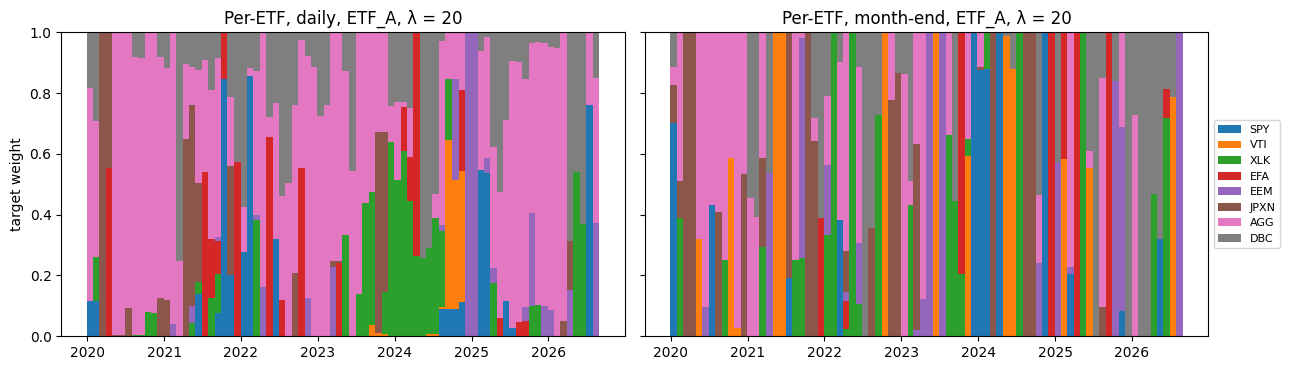

lam                          0.1   1.0   10.0  20.0  50.0
strategy           universe                              
Classic Markowitz  ETF_A     0.99  0.61  0.00  0.10  0.17
                   ETF_B     0.83  0.60  0.00  0.00  0.00
Per-ETF, daily     ETF_A     0.93  0.86  0.31  0.16  0.16
                   ETF_B     0.99  0.81  0.16  0.11  0.06
Per-ETF, month-end ETF_A     1.00  0.96  0.57  0.39  0.21
                   ETF_B     0.99  0.94  0.76  0.50  0.24
Pooled, daily      ETF_A     0.99  0.84  0.03  0.04  0.07
                   ETF_B     1.00  0.63  0.06  0.03  0.03


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
colors = plt.cm.tab10(np.arange(len(config.ETF_A)))
for ax, name in zip(axes, ("Per-ETF, daily", "Per-ETF, month-end")):
    w = weights[(name, "ETF_A", 20.0)].pivot(index="date", columns="ticker", values="target")[config.ETF_A]
    ax.stackplot(w.index, w.T.to_numpy(), labels=config.ETF_A, colors=colors, step="post")
    ax.set_title(f"{name}, ETF_A, λ = 20")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("target weight")
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

# Share of months with one ETF above 90%
last = pd.Timestamp(config.PAPER_LAST_MONTH) - pd.offsets.MonthEnd(1)
single = pd.DataFrame([{"strategy": n, "universe": u, "lam": l,
                        "share": (w.groupby("date")["target"].max().loc[:last] > 0.9).mean()}
                       for (n, u, l), w in weights.items()])
print(single.pivot_table(index=["strategy", "universe"], columns="lam", values="share").round(2).to_string())

## 8. Save

In [9]:
out = summary.reset_index().merge(quality.reset_index().rename(columns={"variant": "strategy"}),
                                  on=["strategy", "universe"], how="left")
out.to_csv(DIRS["reports"] / "D2 Per-ETF Forecast Results.csv", index=False)